# Project 3: Word Embeddings

**Alok Dubey**  
**University of the Cumberlands**  
**Course:** Deep Learning and Natural Language Processing (PhDAI-831-A01)  
**Term:** Fall 2026 – First Bi-Term  

## Project Objective

The purpose of this project is to explore numerical representations of text using Term Frequency-Inverse Document Frequency (TF-IDF) and dimensionality reduction.

In this project, a collection of text documents will first be transformed into TF-IDF vectors. Because TF-IDF representations can contain many dimensions, Principal Component Analysis (PCA) concepts will then be applied manually to reduce the dimensionality of the data while preserving as much variance as possible.

The implementation will demonstrate the following steps:

1. Convert text documents into TF-IDF vectors.
2. Compute the mean of each feature.
3. Center the data by subtracting the feature means.
4. Compute the covariance matrix.
5. Calculate the eigenvalues and eigenvectors of the covariance matrix.
6. Sort the eigenvalues and corresponding eigenvectors.
7. Select the principal components associated with the largest eigenvalues.
8. Project the original data into a lower-dimensional representation.
9. Measure the amount of variance preserved after dimensionality reduction.

The project will also provide a plain-English explanation of each mathematical concept and computational step.

In [1]:
import sys
import numpy as np
import pandas as pd
import sklearn
import matplotlib

print("Python version      :", sys.version.split()[0])
print("NumPy version       :", np.__version__)
print("Pandas version      :", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Matplotlib version  :", matplotlib.__version__)

Python version      : 3.11.9
NumPy version       : 1.26.4
Pandas version      : 2.3.3
Scikit-learn version: 1.8.0
Matplotlib version  : 3.10.8


## Sample Document Corpus and TF-IDF Representation

To demonstrate dimensionality reduction clearly, this project uses a small collection of documents from three general topics: technology, sports, and business.

A small corpus is appropriate because the objective of the project is to explicitly show the mathematical steps involved in dimensionality reduction, including the mean vector, centered data, covariance matrix, eigenvalues, and eigenvectors.

### TF-IDF

Term Frequency-Inverse Document Frequency (TF-IDF) converts text documents into numerical vectors.

- **Term Frequency (TF)** measures how frequently a word appears within a document.
- **Inverse Document Frequency (IDF)** gives greater importance to words that appear in fewer documents and reduces the importance of words that occur across many documents.

Conceptually:

\[
\text{TF-IDF}(t,d)=\text{TF}(t,d)\times\text{IDF}(t)
\]

where \(t\) represents a term and \(d\) represents a document.

As a result, words that are frequent in a particular document but relatively uncommon across the entire document collection receive higher TF-IDF values.

The TF-IDF matrix will serve as the high-dimensional numerical representation that will later be reduced using Principal Component Analysis (PCA) concepts.

In [2]:
documents = [
    # Technology
    "Artificial intelligence is transforming data analysis.",
    "Neural networks learn patterns from large datasets.",
    "Machine learning models can classify text documents.",
    "Cloud computing provides scalable data processing.",

    # Sports
    "The basketball team won the championship game.",
    "The football player scored the winning goal.",
    "The coach prepared the team for the tournament.",
    "Fans celebrated after the final match.",

    # Business
    "The company reported strong quarterly revenue.",
    "Investors responded positively to the earnings report.",
    "The stock market reacted to economic news.",
    "Businesses use analytics to improve decision making."
]

labels = [
    "Technology", "Technology", "Technology", "Technology",
    "Sports", "Sports", "Sports", "Sports",
    "Business", "Business", "Business", "Business"
]

print("Number of documents:", len(documents))
print("\nSample documents:")
for i, (doc, label) in enumerate(zip(documents, labels), start=1):
    print(f"{i:2d}. [{label}] {doc}")

Number of documents: 12

Sample documents:
 1. [Technology] Artificial intelligence is transforming data analysis.
 2. [Technology] Neural networks learn patterns from large datasets.
 3. [Technology] Machine learning models can classify text documents.
 4. [Technology] Cloud computing provides scalable data processing.
 5. [Sports] The basketball team won the championship game.
 6. [Sports] The football player scored the winning goal.
 7. [Sports] The coach prepared the team for the tournament.
 8. [Sports] Fans celebrated after the final match.
 9. [Business] The company reported strong quarterly revenue.
10. [Business] Investors responded positively to the earnings report.
11. [Business] The stock market reacted to economic news.
12. [Business] Businesses use analytics to improve decision making.


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert the documents into TF-IDF vectors.
# Stop words are removed, but all remaining vocabulary terms are retained.
vectorizer = TfidfVectorizer(stop_words="english")

tfidf_matrix = vectorizer.fit_transform(documents)
feature_names = vectorizer.get_feature_names_out()

# Convert the sparse TF-IDF matrix to a dense NumPy array
# so that we can manually perform the PCA calculations.
X = tfidf_matrix.toarray()

tfidf_df = pd.DataFrame(
    X,
    columns=feature_names,
    index=[f"D{i}" for i in range(1, len(documents) + 1)]
)

print("TF-IDF matrix shape:", X.shape)
print("Number of TF-IDF features:", len(feature_names))

print("\nSelected TF-IDF features:")
print(feature_names)

print("\nFirst 10 TF-IDF features:")
display(tfidf_df.iloc[:, :10].round(3))

print("\nNumber of non-zero TF-IDF values in each document:")
for i, row in enumerate(X, start=1):
    print(f"D{i:2d}: {np.count_nonzero(row)}")

TF-IDF matrix shape: (12, 60)
Number of TF-IDF features: 60

Selected TF-IDF features:
['analysis' 'analytics' 'artificial' 'basketball' 'businesses'
 'celebrated' 'championship' 'classify' 'cloud' 'coach' 'company'
 'computing' 'data' 'datasets' 'decision' 'documents' 'earnings'
 'economic' 'fans' 'final' 'football' 'game' 'goal' 'improve'
 'intelligence' 'investors' 'large' 'learn' 'learning' 'machine' 'making'
 'market' 'match' 'models' 'networks' 'neural' 'news' 'patterns' 'player'
 'positively' 'prepared' 'processing' 'provides' 'quarterly' 'reacted'
 'report' 'reported' 'responded' 'revenue' 'scalable' 'scored' 'stock'
 'strong' 'team' 'text' 'tournament' 'transforming' 'use' 'winning' 'won']

First 10 TF-IDF features:


,analysis,analytics,artificial,basketball,businesses,celebrated,championship,classify,cloud,coach
D1,0.459,0.000,0.459,0.000,0.000,0.0,0.000,0.000,0.000,0.000
D2,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000
D3,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.408,0.000,0.000
D4,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.417,0.000
D5,0.000,0.000,0.000,0.459,0.000,0.0,0.459,0.000,0.000,0.000
D6,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000
D7,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.517
D8,0.000,0.000,0.000,0.000,0.000,0.5,0.000,0.000,0.000,0.000
D9,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000
D10,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000,0.000



Number of non-zero TF-IDF values in each document:
D 1: 5
D 2: 6
D 3: 6
D 4: 6
D 5: 5
D 6: 5
D 7: 4
D 8: 4
D 9: 5
D10: 5
D11: 5
D12: 6


## Understanding the TF-IDF Matrix and Dimensionality Reduction

The TF-IDF transformation produced a matrix containing **12 documents and 60 features**.

Each row represents one document, while each column represents one vocabulary term. A TF-IDF value indicates the relative importance of a term within a particular document compared with the full document collection.

Therefore, the TF-IDF data matrix can be represented as:

\[
X \in \mathbb{R}^{12 \times 60}
\]

where:

- \(12\) is the number of documents.
- \(60\) is the number of TF-IDF features.

Although TF-IDF provides a useful numerical representation of text, the number of dimensions can become very large when working with realistic text collections containing thousands or even millions of vocabulary terms.

Dimensionality reduction attempts to represent the same data using fewer dimensions while preserving as much of the important variation in the original data as possible.

In this project, the main mathematical steps of Principal Component Analysis (PCA) will be implemented manually rather than using a built-in PCA function. The process consists of:

1. Computing the mean of each TF-IDF feature.
2. Centering the data around zero.
3. Computing the covariance matrix.
4. Finding the eigenvalues and eigenvectors of the covariance matrix.
5. Sorting the eigenvectors according to their eigenvalues.
6. Selecting the directions that preserve the greatest amount of variance.
7. Projecting the original TF-IDF vectors into a lower-dimensional space.

The resulting representation will contain fewer dimensions while attempting to preserve the most important structure of the original TF-IDF data.

In [4]:
# Compute the mean of each TF-IDF feature
mean_vector = np.mean(X, axis=0)

# Center the data by subtracting the mean vector
X_centered = X - mean_vector

print("Mean vector shape:", mean_vector.shape)
print("Centered data shape:", X_centered.shape)

print("\nFirst 10 feature means:")
for feature, mean_value in zip(feature_names[:10], mean_vector[:10]):
    print(f"{feature:15s}: {mean_value:.6f}")

print("\nFirst document before centering (first 10 features):")
print(np.round(X[0, :10], 4))

print("\nFirst document after centering (first 10 features):")
print(np.round(X_centered[0, :10], 4))

print("\nMean of centered features (first 10):")
print(np.round(np.mean(X_centered, axis=0)[:10], 10))

Mean vector shape: (60,)
Centered data shape: (12, 60)

First 10 feature means:
analysis       : 0.038286
analytics      : 0.034021
artificial     : 0.038286
basketball     : 0.038286
businesses     : 0.034021
celebrated     : 0.041667
championship   : 0.038286
classify       : 0.034021
cloud          : 0.034790
coach          : 0.043105

First document before centering (first 10 features):
[0.4594 0.     0.4594 0.     0.     0.     0.     0.     0.     0.    ]

First document after centering (first 10 features):
[ 0.4211 -0.034   0.4211 -0.0383 -0.034  -0.0417 -0.0383 -0.034  -0.0348
 -0.0431]

Mean of centered features (first 10):
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## Mean Centering

Before computing the covariance matrix, the TF-IDF data is centered by subtracting the mean of each feature.

For feature \(j\), the mean is calculated as:

\[
\mu_j = \frac{1}{n}\sum_{i=1}^{n}X_{ij}
\]

where:

- \(n\) is the number of documents.
- \(X_{ij}\) is the TF-IDF value for document \(i\) and feature \(j\).

The centered data is then calculated as:

\[
X_c = X - \mu
\]

This shifts each feature so that its average value becomes approximately zero.

Mean centering is important because PCA is based on variation around the average. By centering the data, the covariance matrix reflects how features vary relative to their means rather than being influenced by their original absolute values.

For example, the TF-IDF value for the feature **analysis** in the first document was approximately \(0.4594\), while the mean value of that feature across all documents was approximately \(0.0383\). After centering:

\[
0.4594 - 0.0383 \approx 0.4211
\]

Features that were absent from the first document can have negative centered values because their original TF-IDF value was \(0\), which is below the average value of that feature.

After centering, the mean of every feature is approximately zero, confirming that the transformation was performed correctly.

In [5]:
# Number of documents
n_samples = X_centered.shape[0]

# Compute the covariance matrix manually
covariance_matrix = (X_centered.T @ X_centered) / (n_samples - 1)

# Verify the manual calculation using NumPy
covariance_check = np.cov(X_centered, rowvar=False)

print("Covariance matrix shape:", covariance_matrix.shape)
print(
    "Manual covariance matches np.cov:",
    np.allclose(covariance_matrix, covariance_check)
)

print("\nTop-left 10 x 10 section of the covariance matrix:")
covariance_df = pd.DataFrame(
    covariance_matrix,
    index=feature_names,
    columns=feature_names
)

display(covariance_df.iloc[:10, :10].round(4))

Covariance matrix shape: (60, 60)
Manual covariance matches np.cov: True

Top-left 10 x 10 section of the covariance matrix:


,analysis,analytics,artificial,basketball,businesses,celebrated,championship,classify,cloud,coach
analysis,0.0176,-0.0014,0.0176,-0.0016,-0.0014,-0.0017,-0.0016,-0.0014,-0.0015,-0.0018
analytics,-0.0014,0.0139,-0.0014,-0.0014,0.0139,-0.0015,-0.0014,-0.0013,-0.0013,-0.0016
artificial,0.0176,-0.0014,0.0176,-0.0016,-0.0014,-0.0017,-0.0016,-0.0014,-0.0015,-0.0018
basketball,-0.0016,-0.0014,-0.0016,0.0176,-0.0014,-0.0017,0.0176,-0.0014,-0.0015,-0.0018
businesses,-0.0014,0.0139,-0.0014,-0.0014,0.0139,-0.0015,-0.0014,-0.0013,-0.0013,-0.0016
celebrated,-0.0017,-0.0015,-0.0017,-0.0017,-0.0015,0.0208,-0.0017,-0.0015,-0.0016,-0.0020
championship,-0.0016,-0.0014,-0.0016,0.0176,-0.0014,-0.0017,0.0176,-0.0014,-0.0015,-0.0018
classify,-0.0014,-0.0013,-0.0014,-0.0014,-0.0013,-0.0015,-0.0014,0.0139,-0.0013,-0.0016
cloud,-0.0015,-0.0013,-0.0015,-0.0015,-0.0013,-0.0016,-0.0015,-0.0013,0.0145,-0.0016
coach,-0.0018,-0.0016,-0.0018,-0.0018,-0.0016,-0.0020,-0.0018,-0.0016,-0.0016,0.0223


## Understanding the Covariance Matrix

The covariance matrix describes how pairs of TF-IDF features vary together across the document collection.

For centered data, the covariance matrix is calculated as:

\[
C = \frac{1}{n-1}X_c^T X_c
\]

where:

- \(X_c\) is the centered TF-IDF matrix.
- \(X_c^T\) is the transpose of the centered matrix.
- \(n\) is the number of documents.
- \(C\) is the covariance matrix.

Because the TF-IDF representation contains 60 features, the resulting covariance matrix has dimensions:

\[
60 \times 60
\]

Each row and column corresponds to one TF-IDF feature.

### Interpreting Covariance Values

A **positive covariance** indicates that two features tend to increase or decrease together across the documents.

For example, the features **analysis** and **artificial** have a covariance of approximately:

\[
0.0176
\]

These two terms appear together in the same document in this corpus, producing similar patterns across the document collection.

Similarly, **basketball** and **championship** have a positive covariance of approximately:

\[
0.0176
\]

because they also occur together and therefore vary similarly across the documents.

A **negative covariance** indicates that when one feature is relatively high, the other tends to be relatively low. For example, technology-related terms such as **analysis** have negative covariance with sports-related terms such as **basketball** because they occur in different documents in this sample corpus.

A covariance close to zero indicates little linear relationship between the variation of two features.

### Diagonal Values

The values along the diagonal of the covariance matrix represent the variance of each individual feature.

For example, the diagonal value for **analysis** is approximately:

\[
0.0176
\]

This represents the amount of variation in the TF-IDF values of the feature **analysis** across the 12 documents.

The covariance matrix is important because PCA analyzes this matrix to identify the directions in which the TF-IDF data varies the most.

In [6]:
# Compute eigenvalues and eigenvectors of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eigh(covariance_matrix)

print("Number of eigenvalues :", len(eigenvalues))
print("Eigenvector matrix shape:", eigenvectors.shape)

print("\nFirst 10 eigenvalues returned by np.linalg.eigh:")
print(np.round(eigenvalues[:10], 6))

print("\nLast 10 eigenvalues returned by np.linalg.eigh:")
print(np.round(eigenvalues[-10:], 6))

Number of eigenvalues : 60
Eigenvector matrix shape: (60, 60)

First 10 eigenvalues returned by np.linalg.eigh:
[-0. -0. -0. -0. -0. -0. -0. -0. -0. -0.]

Last 10 eigenvalues returned by np.linalg.eigh:
[0.078048 0.090909 0.090909 0.090909 0.090909 0.090909 0.090909 0.090909
 0.100199 0.105615]


In [7]:
# Get indices that would sort the eigenvalues from largest to smallest
sorted_indices = np.argsort(eigenvalues)[::-1]

# Sort eigenvalues
eigenvalues_sorted = eigenvalues[sorted_indices]

# Reorder eigenvectors using the same indices
eigenvectors_sorted = eigenvectors[:, sorted_indices]

print("Sorted eigenvalues from largest to smallest:")
print(np.round(eigenvalues_sorted, 6))

# Count eigenvalues that are meaningfully greater than zero
nonzero_eigenvalues = np.sum(eigenvalues_sorted > 1e-10)

print("\nNumber of meaningful non-zero eigenvalues:", nonzero_eigenvalues)

print("\nTop 5 eigenvalues:")
for i, value in enumerate(eigenvalues_sorted[:5], start=1):
    print(f"PC{i}: {value:.6f}")

Sorted eigenvalues from largest to smallest:
[ 0.105615  0.100199  0.090909  0.090909  0.090909  0.090909  0.090909
  0.090909  0.090909  0.078048  0.074975  0.        0.        0.
  0.        0.        0.        0.        0.        0.        0.
  0.        0.        0.        0.        0.        0.        0.
  0.        0.        0.        0.        0.        0.       -0.
 -0.       -0.       -0.       -0.       -0.       -0.       -0.
 -0.       -0.       -0.       -0.       -0.       -0.       -0.
 -0.       -0.       -0.       -0.       -0.       -0.       -0.
 -0.       -0.       -0.       -0.      ]

Number of meaningful non-zero eigenvalues: 11

Top 5 eigenvalues:
PC1: 0.105615
PC2: 0.100199
PC3: 0.090909
PC4: 0.090909
PC5: 0.090909


## Understanding Eigenvalues and Eigenvectors

After computing the covariance matrix, PCA identifies the directions in which the data varies the most by calculating the eigenvalues and eigenvectors of the covariance matrix.

The relationship is expressed as:

\[
Cv = \lambda v
\]

where:

- \(C\) is the covariance matrix.
- \(v\) is an eigenvector.
- \(\lambda\) is the corresponding eigenvalue.

### Eigenvectors

An eigenvector represents a direction in the original TF-IDF feature space.

Because the original TF-IDF representation contains 60 features, each eigenvector contains 60 values. These values define a new direction formed from a combination of the original TF-IDF features.

In PCA, these directions become the principal components.

### Eigenvalues

An eigenvalue indicates how much variance is captured along its corresponding eigenvector.

A larger eigenvalue means that the associated direction captures more variation in the data and therefore contains more information about the structure of the document collection.

The eigenvalues were sorted from largest to smallest so that the most informative directions appear first.

For this dataset, the largest eigenvalues are approximately:

\[
\lambda_1 = 0.105615
\]

\[
\lambda_2 = 0.100199
\]

\[
\lambda_3 = 0.090909
\]

The eigenvectors associated with these eigenvalues therefore capture the greatest amounts of variance in the TF-IDF data.

### Why Only 11 Eigenvalues Are Meaningfully Non-Zero

Although the covariance matrix contains 60 eigenvalues, only 11 are meaningfully greater than zero.

This occurs because the dataset contains only 12 documents. After mean centering, the maximum number of independent directions of variation is:

\[
n - 1 = 12 - 1 = 11
\]

Therefore, the remaining eigenvalues are theoretically zero. Small values displayed as \(0\) or \(-0\) are the result of floating-point numerical precision and do not represent meaningful negative variance.

The next step is to determine how much of the total variance is explained by each principal component.

In [8]:
# Calculate the proportion of total variance explained by each component
explained_variance_ratio = eigenvalues_sorted / np.sum(eigenvalues_sorted)

# Calculate cumulative explained variance
cumulative_variance = np.cumsum(explained_variance_ratio)

print("Explained variance by principal component:\n")

for i in range(nonzero_eigenvalues):
    print(
        f"PC{i+1:2d}: "
        f"{explained_variance_ratio[i] * 100:6.2f}%   "
        f"Cumulative: {cumulative_variance[i] * 100:6.2f}%"
    )

# Select enough principal components to preserve at least 80% of the variance
variance_threshold = 0.80

k = np.argmax(cumulative_variance >= variance_threshold) + 1

print(f"\nVariance preservation target : {variance_threshold * 100:.0f}%")
print(f"Number of components needed : {k}")
print(
    f"Actual variance preserved   : "
    f"{cumulative_variance[k - 1] * 100:.2f}%"
)

# Select the eigenvectors associated with the largest eigenvalues
principal_components = eigenvectors_sorted[:, :k]

print("\nPrincipal component matrix shape:", principal_components.shape)

Explained variance by principal component:

PC 1:  10.61%   Cumulative:  10.61%
PC 2:  10.07%   Cumulative:  20.68%
PC 3:   9.13%   Cumulative:  29.82%
PC 4:   9.13%   Cumulative:  38.95%
PC 5:   9.13%   Cumulative:  48.08%
PC 6:   9.13%   Cumulative:  57.22%
PC 7:   9.13%   Cumulative:  66.35%
PC 8:   9.13%   Cumulative:  75.49%
PC 9:   9.13%   Cumulative:  84.62%
PC10:   7.84%   Cumulative:  92.47%
PC11:   7.53%   Cumulative: 100.00%

Variance preservation target : 80%
Number of components needed : 9
Actual variance preserved   : 84.62%

Principal component matrix shape: (60, 9)


In [9]:
# Project the centered TF-IDF data onto the selected principal components
X_reduced = X_centered @ principal_components

# Create column names for the reduced representation
pc_columns = [f"PC{i}" for i in range(1, k + 1)]

# Store the reduced data in a DataFrame
reduced_df = pd.DataFrame(
    X_reduced,
    columns=pc_columns,
    index=[f"D{i}" for i in range(1, len(documents) + 1)]
)

print("Original TF-IDF shape :", X.shape)
print("Reduced data shape    :", X_reduced.shape)

print(
    f"\nDimensionality reduced from {X.shape[1]} "
    f"features to {X_reduced.shape[1]} principal components."
)

print(
    f"Variance preserved: "
    f"{cumulative_variance[k - 1] * 100:.2f}%"
)

print("\nReduced document representation:")
display(reduced_df.round(4))

Original TF-IDF shape : (12, 60)
Reduced data shape    : (12, 9)

Dimensionality reduced from 60 features to 9 principal components.
Variance preserved: 84.62%

Reduced document representation:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9
D1,0.4184,0.5415,0.0000,-0.0000,-0.0000,0.0000,0.0000,0.0000,-0.0000
D2,0.0525,-0.2081,0.4324,0.1073,0.5452,0.1016,-0.4059,-0.3538,-0.2809
D3,0.0525,-0.2081,-0.3255,0.2335,-0.3792,0.0466,-0.5248,-0.3002,0.4505
D4,0.4184,0.5415,-0.0000,-0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000
D5,-0.6283,0.2910,0.0000,0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000
D6,0.0525,-0.2081,-0.3731,0.0043,-0.0728,-0.2862,-0.2769,0.4835,-0.5815
D7,-0.6283,0.2910,0.0000,0.0000,0.0000,-0.0000,-0.0000,0.0000,0.0000
D8,0.0525,-0.2081,0.6096,-0.0288,-0.1513,-0.3760,0.0060,0.4348,0.3863
D9,0.0525,-0.2081,-0.0046,-0.1768,-0.2620,-0.4417,0.4485,-0.5734,-0.2236
D10,0.0525,-0.2081,-0.2857,0.5697,0.4251,0.0227,0.4766,0.1225,0.2131


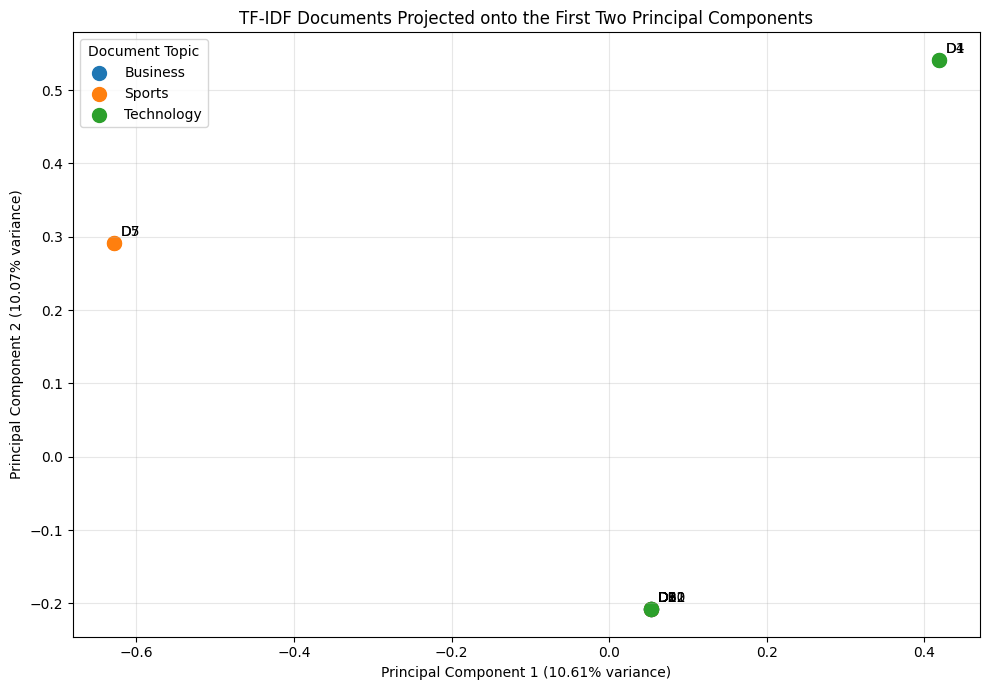

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

# Plot documents by topic using the first two principal components
for label in sorted(set(labels)):
    indices = [i for i, value in enumerate(labels) if value == label]

    plt.scatter(
        X_reduced[indices, 0],
        X_reduced[indices, 1],
        s=100,
        label=label
    )

# Add document labels to each point
for i in range(len(documents)):
    plt.annotate(
        f"D{i + 1}",
        (X_reduced[i, 0], X_reduced[i, 1]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(
    f"Principal Component 1 "
    f"({explained_variance_ratio[0] * 100:.2f}% variance)"
)

plt.ylabel(
    f"Principal Component 2 "
    f"({explained_variance_ratio[1] * 100:.2f}% variance)"
)

plt.title("TF-IDF Documents Projected onto the First Two Principal Components")
plt.legend(title="Document Topic")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Interpretation and Conclusion

### Interpretation of the Reduced Representation

The original TF-IDF representation contained 60 features for each of the 12 documents. After calculating the covariance matrix, eigenvalues, and eigenvectors, the principal components were ranked according to the amount of variance they explained.

Using an 80% cumulative variance threshold, the first 9 principal components were selected. These components preserve approximately:

\[
84.62\%
\]

of the total variance in the original TF-IDF representation.

Therefore, the dimensionality of the data was reduced from:

\[
60 \text{ features} \rightarrow 9 \text{ principal components}
\]

while retaining most of the variation present in the original dataset.

### Interpretation of the Two-Dimensional Visualization

For visualization purposes, only the first two principal components were plotted.

Principal Component 1 explains approximately:

\[
10.61\%
\]

of the total variance, while Principal Component 2 explains approximately:

\[
10.07\%
\]

Together, the two-dimensional visualization represents approximately:

\[
20.68\%
\]

of the total variance.

Some documents overlap in the two-dimensional plot. For example, documents D1 and D4 have the same coordinates on the first two principal components, and documents D5 and D7 also overlap. Several additional documents appear at approximately the same location.

This does not mean that these documents have identical complete representations. They may differ substantially along Principal Components 3 through 9. The visualization therefore provides only a simplified view of the reduced data.

The topic labels were not used when computing the principal components. PCA is an unsupervised dimensionality-reduction method, so the Technology, Sports, and Business labels were added only after the transformation to assist with interpretation.

## Plain-English Explanation of the Algorithm

The dimensionality-reduction process used in this project can be explained in the following steps:

1. **Convert text into numbers:**  
   TF-IDF converts every document into a numerical vector. Words that are important within a particular document but relatively uncommon across the entire collection receive higher TF-IDF values.

2. **Calculate the feature means:**  
   The average TF-IDF value of each feature is calculated across all documents.

3. **Center the data:**  
   Each feature mean is subtracted from its corresponding TF-IDF values. This moves the average of every feature to approximately zero and allows PCA to analyze variation around the mean.

4. **Calculate the covariance matrix:**  
   The covariance matrix measures how pairs of TF-IDF features vary together. Positive covariance indicates that two features tend to vary in the same direction, while negative covariance indicates that they tend to vary in opposite directions.

5. **Calculate eigenvalues and eigenvectors:**  
   Eigenvectors identify important directions of variation in the data. The corresponding eigenvalues indicate how much variance is captured along each direction.

6. **Sort the principal components:**  
   The eigenvalues are sorted from largest to smallest, and the corresponding eigenvectors are reordered in the same way. The components with the largest eigenvalues preserve the greatest amount of information.

7. **Select the most informative components:**  
   Principal components are retained until at least 80% of the total variance is preserved. For this dataset, 9 components preserve approximately 84.62% of the variance.

8. **Project the original data:**  
   The centered TF-IDF vectors are multiplied by the selected eigenvectors to create a lower-dimensional representation of the documents.

## Conclusion

This project demonstrated how high-dimensional TF-IDF document vectors can be reduced to a smaller numerical representation using the mathematical principles of Principal Component Analysis.

The implementation explicitly calculated the feature means, centered the TF-IDF data, constructed the covariance matrix, calculated and sorted eigenvalues and eigenvectors, measured explained variance, selected principal components, and projected the original data into a lower-dimensional space.

The original 60-dimensional TF-IDF representation was reduced to 9 principal components while preserving approximately 84.62% of the total variance. This demonstrates how dimensionality reduction can create more compact representations of text while retaining much of the important information contained in the original feature space.

The project also illustrates an important tradeoff in dimensionality reduction. A very small number of dimensions, such as the two dimensions used for visualization, provides an intuitive graphical representation but preserves less information. Retaining additional principal components provides a better balance between dimensionality reduction and information preservation.

## References

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., ... Oliphant, T. E. (2020). Array programming with NumPy. *Nature, 585*, 357–362. https://doi.org/10.1038/s41586-020-2649-2

Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A: Mathematical, Physical and Engineering Sciences, 374*(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management, 24*(5), 513–523. https://doi.org/10.1016/0306-4573(88)90021-0

## AI Use Disclosure

ChatGPT by OpenAI was used as a learning and development aid during this project. It assisted with brainstorming the project structure, explaining TF-IDF, covariance, eigenvalues, eigenvectors, and Principal Component Analysis concepts, and reviewing the clarity of the Python code and written explanations.

The implementation was executed by the author in the project's Python environment. The author reviewed and verified the outputs at each major stage, including the TF-IDF matrix, feature means, centered data, covariance matrix, eigenvalues, eigenvectors, explained variance, dimensionality reduction, and visualization. The manual covariance calculation was also compared with NumPy's built-in covariance calculation as an additional verification step.

The author reviewed the final notebook for accuracy, originality, and consistency and remains responsible for the content and results presented in this submission.